## Word Embeddings

### Sentiment Analysis

In [11]:
from keras.datasets import imdb
import importlib
import numpy as np

import matplotlib.pyplot as plt
from numpy.random import seed
seed(1)

import  tensorflow as tf

tf.random.set_seed(1234)
from tensorflow.keras.layers import Embedding, Dense, Flatten,Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras import Input
from keras import preprocessing
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras import regularizers

### Helper Function

In [12]:
def display_metrics(history):

    n = len(history.history["loss"])

    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(range(n), (history.history["loss"]),'r', label="Train Loss")
    ax.plot(range(n), (history.history["val_loss"]),'b', label="Validation Loss")
    ax.legend()
    ax.set_title('Loss over iterations')

    ax = fig.add_subplot(1, 2, 2)
    ax.plot(range(n), (history.history["acc"]),'r', label="Train Acc")
    ax.plot(range(n), (history.history["val_acc"]),'b', label="Validation Acc")
    ax.legend(loc='lower right')
    ax.set_title('Accuracy over iterations')

def plot_embedding(X_embedded,start=100,stop=300,sample=10):
    fig, ax = plt.subplots()
    ax.scatter(X_embedded[start:stop:sample,0], X_embedded[start:stop:sample,1])
    for i in range(start,stop,sample):
        ax.annotate(REVERSE_LOOKUP[i+1], (X_embedded[i,0], X_embedded[i,1]))

def rotten_tomato_score(p_yx):
    return ["rotten"  if p<=0.60 else "fresh"for p in p_yx ]

In [13]:
max_feats = 10000
np.load.__defaults__=(None, True, True, 'ASCII')
importlib.reload(np)

# Correctly pair the X and Y variables
(xtrain, ytrain), (xtest, ytest) = imdb.load_data(num_words=max_feats)

for i,x in enumerate(xtrain[0:3]):
    print("Sequence:",i) 
    print(x)

C:\Users\LEI\AppData\Local\Python\pythoncore-3.14-64\Lib\importlib\__init__.py:129: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  _bootstrap._exec(spec, module)


Sequence: 0
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]
Sequence: 1
[1, 194, 1153, 194, 8255, 78, 228, 5

In [14]:
word_idx = imdb.get_word_index()

In [15]:
REVERSE_LOOKUP = {value:key for key, value in word_idx.items()}

def get_review(x):
    return ' '.join([REVERSE_LOOKUP[index] for index in x])

get_review(xtrain[0])

"the as you with out themselves powerful lets loves their becomes reaching had journalist of lot from anyone to have after out atmosphere never more room and it so heart shows to years of every never going and help moments or of every chest visual movie except her was several of enough more with is now current film as you of mine potentially unfortunately of you than him that with out themselves her get for was camp of you movie sometimes movie that with scary but and to story wonderful that in seeing in character to of 70s musicians with heart had shadows they of here that with her serious to have does when from why what have critics they is you that isn't one will very to as itself with other and in of seen over landed for anyone of and br show's to whether from than out themselves history he name half some br of and odd was two most of mean for 1 any an boat she he should is thought frog but of script you not while history he heart to real at barrel but when from one bit then have t

In [16]:
get_review(xtrain[1])

"the thought solid thought senator do making to is spot nomination assumed while he of jack in where picked as getting on was did hands fact characters to always life thrillers not as me can't in at are br of sure your way of little it strongly random to view of love it so principles of guy it used producer of where it of here icon film of outside to don't all unique some like of direction it if out her imagination below keep of queen he diverse to makes this stretch and of solid it thought begins br senator and budget worthwhile though ok and awaiting for ever better were and diverse for budget look kicked any to of making it out and follows for effects show to show cast this family us scenes more it severe making senator to and finds tv tend to of emerged these thing wants but and an beckinsale cult as it is video do you david see scenery it in few those are of ship for with of wild to one is very work dark they don't do dvd with those them"

In [17]:
for i, x in enumerate(xtrain[0:3]):
    print("length {} of sample {}:".format(i, len(x)))

length 0 of sample 218:
length 1 of sample 189:
length 2 of sample 141:


In [18]:
ytrain = ytrain.astype('int32')

In [19]:
max_length = 20

xtrain_padded = pad_sequences(xtrain, maxlen=max_length)
ytrain_labels = np.array(ytrain).astype('int32')

model = Sequential()
model.add(Input(shape=(20,)))
model.add(Embedding(10000, 8)) 
model.add(Flatten())
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='rmsprop', metrics=['acc'])

history = model.fit(
    xtrain_padded, ytrain_labels, epochs=10, batch_size=30, validation_split=0.2
)

Epoch 1/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - acc: 0.6265 - loss: 0.6667 - val_acc: 0.6936 - val_loss: 0.6106
Epoch 2/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - acc: 0.7512 - loss: 0.5349 - val_acc: 0.7326 - val_loss: 0.5238
Epoch 3/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - acc: 0.7857 - loss: 0.4613 - val_acc: 0.7442 - val_loss: 0.5029
Epoch 4/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.8050 - loss: 0.4261 - val_acc: 0.7510 - val_loss: 0.4986
Epoch 5/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - acc: 0.8177 - loss: 0.4025 - val_acc: 0.7560 - val_loss: 0.4999
Epoch 6/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - acc: 0.8281 - loss: 0.3833 - val_acc: 0.7552 - val_loss: 0.5033
Epoch 7/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - acc: 0.8383 - loss: 0.3657 - val_acc: 0.7560 - val_loss: 0.5080
Epoch 8/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - acc: 0.8497 - loss: 0.3487 - val_acc: 0.7548 - val_loss: 0.5135
Epoch 9/10
667/667 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - ac

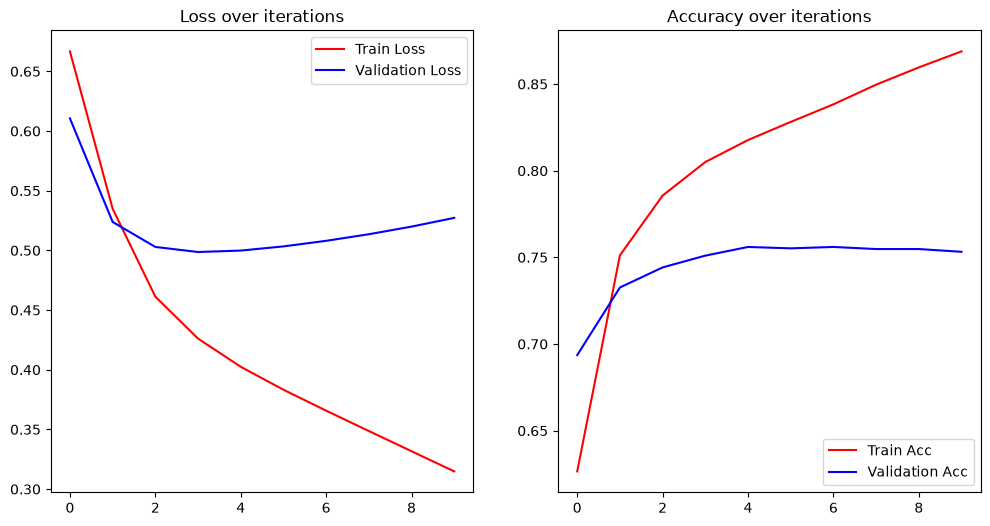

In [20]:
display_metrics(history)

In [24]:
xtest = np.array(xtest).astype('int')
p_yx=model.predict(xtest[0:10])

TypeError: int() argument must be a string, a bytes-like object or a real number, not 'list'

In [23]:
rotten_tomato_score(p_yx)

NameError: name 'p_yx' is not defined

### Visualizing the embedding  weights

In [ ]:
weights=model.layers[0].get_weights()[0]
weights.shape

from sklearn.manifold import TSNE
tsne = TSNE(n_components=2)
X_embedded = tsne.fit_transform(weights)

start=1
stop=600
sample=10
plot_embedding(X_embedded,start,stop,sample)

KeyboardInterrupt: 